In [1]:
import numpy as np 
import matplotlib.pyplot as plt 


In [2]:
index = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

signal = np.array([ -1, 1, 2, 1, 0, -1, 1, 2, 1, -2])

print(index)
print(signal)

[0 1 2 3 4 5 6 7 8 9]
[-1  1  2  1  0 -1  1  2  1 -2]


# Zero Crossing Detection

The objective of this section is to detect positive and negative zero crossings in a signal using reusable functions.

In [3]:
def find_zero_crossings_no_zeros(signs):
    """
    Find positive and negative zero crossings in a sign array
    containing only -1 and +1 values.

    Parameters
    ----------
    signs : np.ndarray
        Array containing signs (-1 or +1).

    Returns
    -------
    i_cross_pos : np.ndarray
        Indices where the signal changes from negative to positive.

    i_cross_neg : np.ndarray
        Indices where the signal changes from positive to negative.
    """

    # Difference between consecutive signs
    diff = np.diff(signs)

    # Negative to positive crossing
    i_cross_pos = np.where(diff > 0)[0]

    # Positive to negative crossing
    i_cross_neg = np.where(diff < 0)[0]

    return i_cross_pos, i_cross_neg

In [4]:
test_signal = np.array([-1, 1, -1, 1, -1])

i_pos, i_neg = find_zero_crossings_no_zeros(test_signal)

print("Positive crossings :", i_pos)
print("Negative crossings :", i_neg)

Positive crossings : [0 2]
Negative crossings : [1 3]


# Explanation

The function first computes the difference between successive signs.

A positive difference indicates a negative-to-positive transition.

A negative difference indicates a positive-to-negative transition.

The indices are obtained using NumPy's where function.

In [5]:
def propagate_signs_over_zeros(signs):
    """
    Replace zeros with the previous non-zero sign.

    Parameters
    ----------
    signs : np.ndarray
        Array containing -1, 0 and +1 values.

    Returns
    -------
    np.ndarray
        Sign array without zeros.
    """

    signs_no_zeros = signs.copy()

    for i in range(1, len(signs_no_zeros)):
        if signs_no_zeros[i] == 0:
            signs_no_zeros[i] = signs_no_zeros[i - 1]

    return signs_no_zeros

In [6]:
test = np.array([-1, 0, 0, 1])

result = propagate_signs_over_zeros(test)

print(result)

[-1 -1 -1  1]


In [7]:
def find_zero_crossings(signal):
    """
    Find positive and negative zero crossings in a 1D signal.

    Parameters
    ----------
    signal : np.ndarray
        Input signal.

    Returns
    -------
    i_cross_pos : np.ndarray
        Indices of positive crossings.

    i_cross_neg : np.ndarray
        Indices of negative crossings.
    """

    # Convert input to numpy array
    signal = np.asarray(signal)

    # Check that signal is 1D
    if signal.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # Convert values to signs
    signs = np.sign(signal).astype(int)

    # Replace zeros
    signs_no_zeros = propagate_signs_over_zeros(signs)

    # Find crossings
    return find_zero_crossings_no_zeros(signs_no_zeros)

In [8]:
i_pos, i_neg = find_zero_crossings(signal)

print("Positive crossings :", i_pos)
print("Negative crossings :", i_neg)

Positive crossings : [0 5]
Negative crossings : [4 8]


# Explanation of find_zero_crossings

The function first converts the signal into a sign array.

Values become:

positive -> +1
negative -> -1
zero -> 0
Zeros are then replaced by the previous sign value to avoid missing a crossing.

Finally, the function detects transitions between consecutive signs using NumPy.

In [9]:
def test_find_zero_crossings():

    s = np.array([-1, 1, -1, 1, -1])

    i_pos, i_neg = find_zero_crossings(s)

    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    print("Test passed")

In [10]:
test_find_zero_crossings()

Test passed


In [11]:
def find_local_maxima(signal):
    """
    Find local maxima in a 1D signal.

    Parameters
    ----------
    signal : np.ndarray
        Input signal.

    Returns
    -------
    i_local_max : np.ndarray
        Indices of local maxima.
    """

    signal = np.asarray(signal)

    i_local_max = np.where(
        (signal[1:-1] > signal[:-2]) &
        (signal[1:-1] > signal[2:])
    )[0] + 1

    return i_local_max

In [13]:

i_max = find_local_maxima(signal)

print(i_max)


[2 7]


In [15]:
def find_local_minima(signal):
    """
    Find local minima in a 1D signal.

    Parameters
    ----------
    signal : np.ndarray
        Input signal.

    Returns
    -------
    i_local_min : np.ndarray
        Indices of local minima.
    """

    signal = np.asarray(signal)

    i_local_min = np.where(
        (signal[1:-1] < signal[:-2]) &
        (signal[1:-1] < signal[2:])
    )[0] + 1

    return i_local_min

In [16]:
i_min = find_local_minima(signal)

print(i_min)


[5]


# Local Maxima and Minima

A local maximum is a point whose value is greater than its two neighbours.

A local minimum is a point whose value is smaller than its two neighbours.

NumPy allows these points to be detected efficiently using vectorized comparisons.

In [17]:
def plot_signal(i, s):
    """
    Plot the signal.
    """

    plt.plot(i, s, ".-", label="Signal")
    plt.axhline(y=0, color="gray")
    plt.xlabel("Index")
    plt.ylabel("Signal")


In [18]:
def plot_local_maxima(i, s):

    i_max = find_local_maxima(s)

    plt.plot(
        i[i_max],
        s[i_max],
        "^g",
        markersize=10,
        label="Local maxima"
    )

In [19]:
def plot_local_minima(i, s):

    i_min = find_local_minima(s)

    plt.plot(
        i[i_min],
        s[i_min],
        "vr",
        markersize=10,
        label="Local minima"
    )

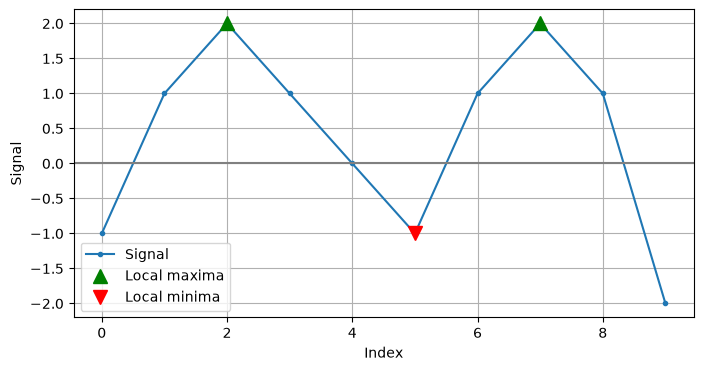

In [20]:
plt.figure(figsize=(8,4))

plot_signal(index, signal)

plot_local_maxima(index, signal)

plot_local_minima(index, signal)

plt.legend()

plt.grid(True)

plt.show()

# Role of Unit Tests

Unit tests verify that the functions work correctly under different conditions.

They help identify programming errors and ensure that future modifications do not break the code.

The provided tests cover:

positive zero crossings,
negative zero crossings,
signals containing zeros,
signals starting with zeros,
signals ending with zeros.
Additional tests were added to check:

signals with no crossings,
signals containing only positive values,
signals containing only negative values,
empty signals.